In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("Unemployment in India.csv")

df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [3]:
# Check dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Region                                   740 non-null    object 
 1   Date                                     740 non-null    object 
 2   Frequency                                740 non-null    object 
 3   Estimated Unemployment Rate (%)          740 non-null    float64
 4   Estimated Employed                       740 non-null    float64
 5   Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                     740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [4]:
df.describe()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [ ]:

df.isnull().sum()

Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64

In [6]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove completely empty rows
df.dropna(how='all', inplace=True)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Convert Date column into datetime format
df['Date'] = pd.to_datetime(
    df['Date'].astype(str).str.strip(),
    format='%d-%m-%Y'
)

print("Data Cleaning Completed!")
print("Cleaned Dataset Shape:", df.shape)

df.head()

Data Cleaning Completed!
Cleaned Dataset Shape: (740, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


In [7]:
# Clean column names
df.columns = df.columns.str.strip()

# Remove empty rows and duplicates
df.dropna(how='all', inplace=True)
df.drop_duplicates(inplace=True)

# Convert Date column
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')

print("Cleaned Dataset:", df.shape)

Cleaned Dataset: (740, 7)


In [8]:
state_unemployment = df.groupby('Region')[
    'Estimated Unemployment Rate (%)'
].mean().sort_values(ascending=False)

print(state_unemployment)

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64


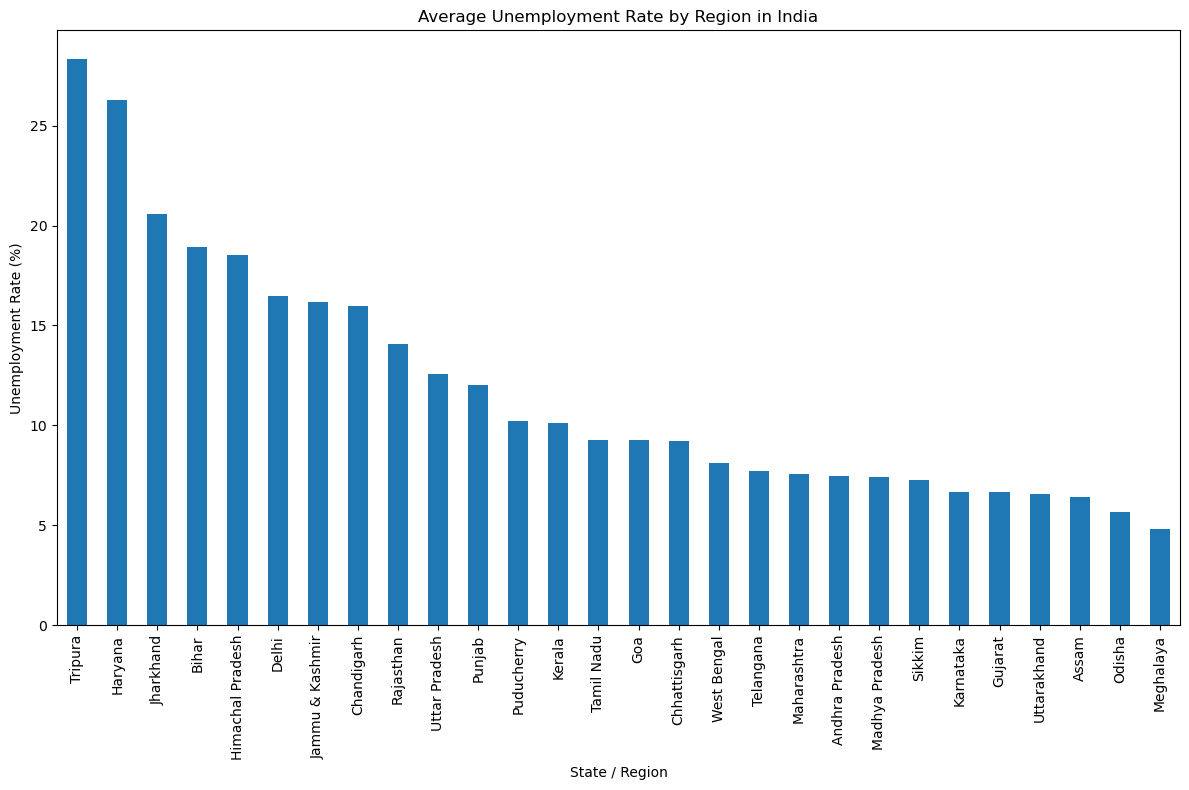

In [9]:
plt.figure(figsize=(12, 8))

state_unemployment.plot(kind='bar')

plt.title('Average Unemployment Rate by Region in India')
plt.xlabel('State / Region')
plt.ylabel('Unemployment Rate (%)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

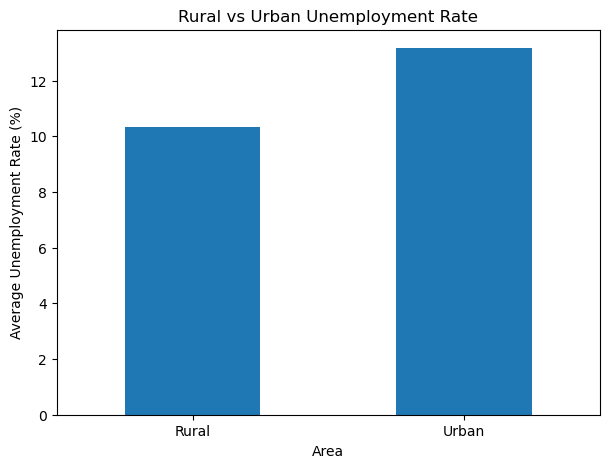

In [10]:
area_comparison = df.groupby('Area')[
    'Estimated Unemployment Rate (%)'
].mean()

area_comparison.plot(kind='bar', figsize=(7, 5))

plt.title('Rural vs Urban Unemployment Rate')
plt.xlabel('Area')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=0)
plt.show()

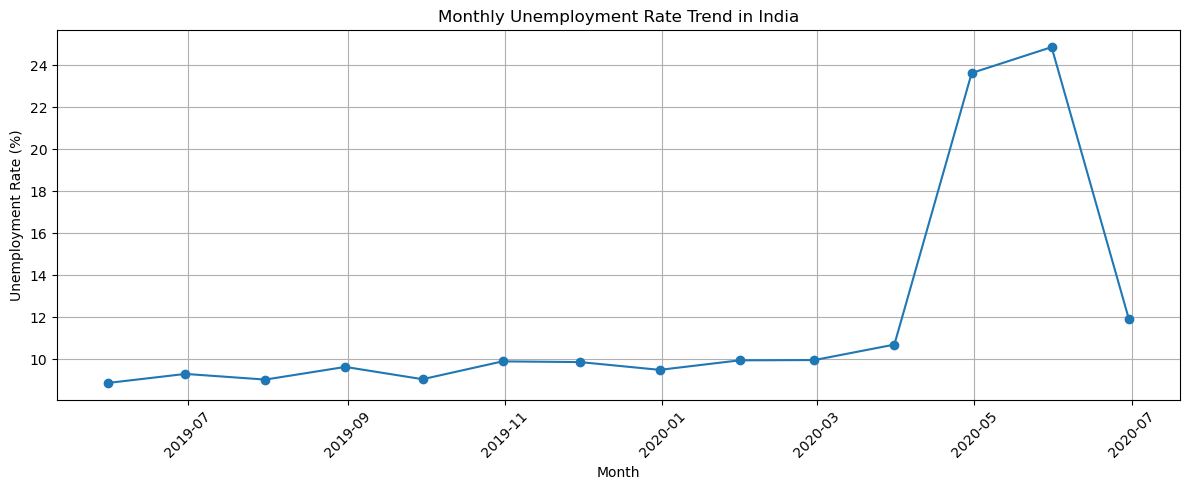

In [11]:
monthly_trend = df.groupby('Date')[
    'Estimated Unemployment Rate (%)'
].mean()

plt.figure(figsize=(12, 5))

plt.plot(monthly_trend.index, monthly_trend.values, marker='o')

plt.title('Monthly Unemployment Rate Trend in India')
plt.xlabel('Month')
plt.ylabel('Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

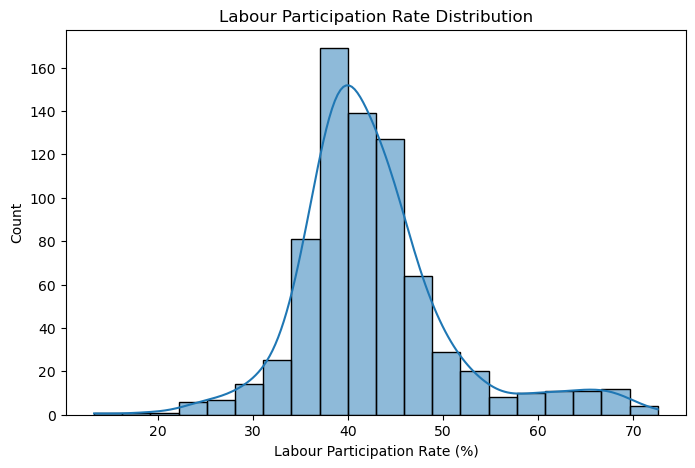

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df['Estimated Labour Participation Rate (%)'],
    bins=20,
    kde=True
)

plt.title('Labour Participation Rate Distribution')
plt.xlabel('Labour Participation Rate (%)')
plt.show()

In [13]:
print("Highest Unemployment Region:")
print(state_unemployment.head(5))

print("\nLowest Unemployment Region:")
print(state_unemployment.tail(5))

Highest Unemployment Region:
Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Name: Estimated Unemployment Rate (%), dtype: float64

Lowest Unemployment Region:
Region
Gujarat        6.663929
Uttarakhand    6.582963
Assam          6.428077
Odisha         5.657857
Meghalaya      4.798889
Name: Estimated Unemployment Rate (%), dtype: float64


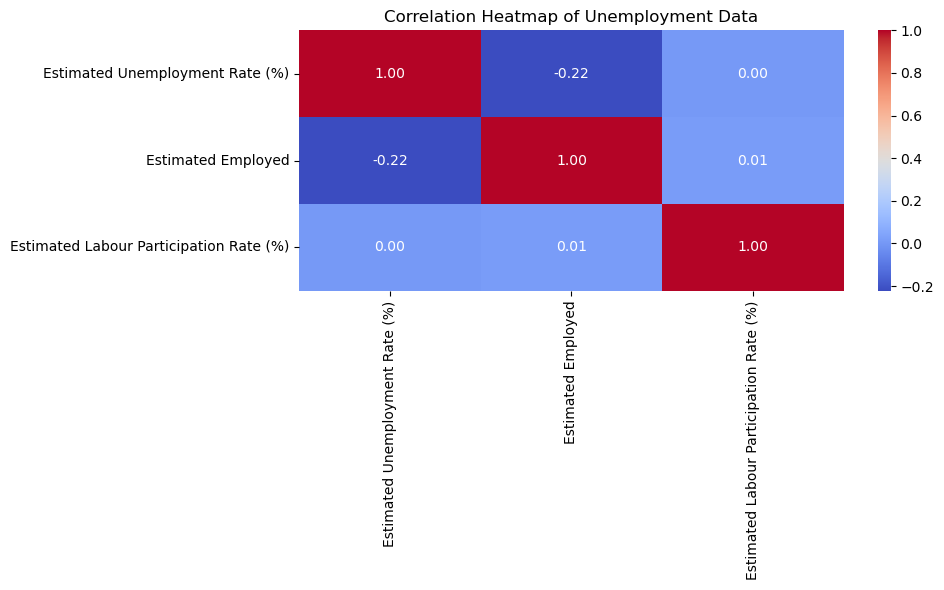

In [14]:
plt.figure(figsize=(10, 6))

corr = df.select_dtypes(include='number').corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of Unemployment Data')
plt.tight_layout()
plt.show()

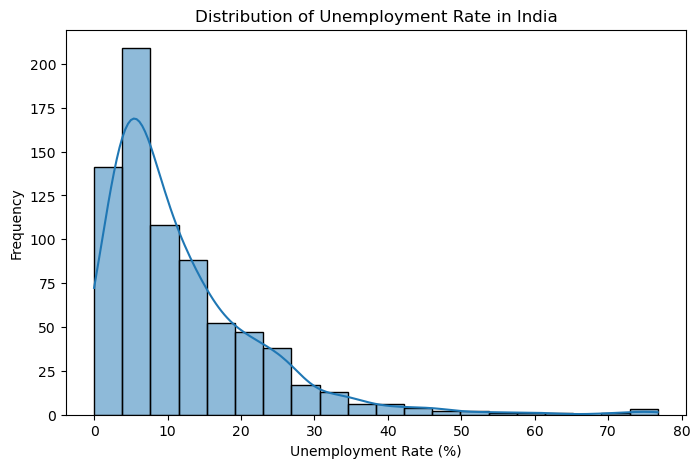

In [15]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df['Estimated Unemployment Rate (%)'],
    bins=20,
    kde=True
)

plt.title('Distribution of Unemployment Rate in India')
plt.xlabel('Unemployment Rate (%)')
plt.ylabel('Frequency')
plt.show()

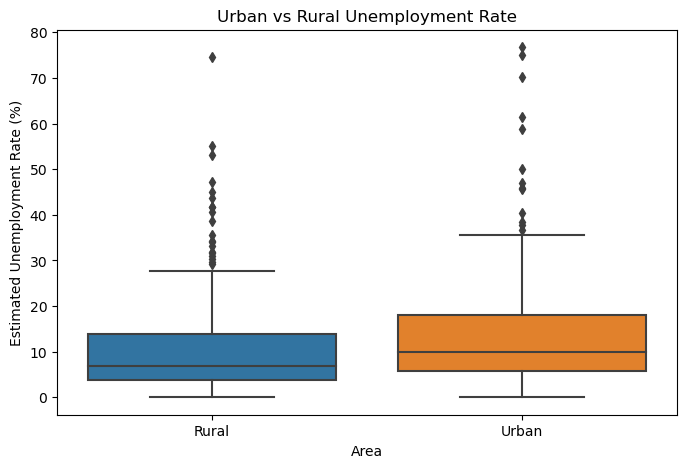

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Area',
    y='Estimated Unemployment Rate (%)'
)

plt.title('Urban vs Rural Unemployment Rate')
plt.show()

In [17]:
print("UNEMPLOYMENT ANALYSIS - KEY FINDINGS")

print("\n1. Average Unemployment Rate:")
print(round(df['Estimated Unemployment Rate (%)'].mean(), 2), "%")

print("\n2. Highest Unemployment Region:")
print(state_unemployment.idxmax())
print(round(state_unemployment.max(), 2), "%")

print("\n3. Lowest Unemployment Region:")
print(state_unemployment.idxmin())
print(round(state_unemployment.min(), 2), "%")

print("\n4. Average Unemployment by Area:")
print(area_comparison)

print("\n5. Total Records Analyzed:")
print(len(df))

UNEMPLOYMENT ANALYSIS - KEY FINDINGS

1. Average Unemployment Rate:
11.79 %

2. Highest Unemployment Region:
Tripura
28.35 %

3. Lowest Unemployment Region:
Meghalaya
4.8 %

4. Average Unemployment by Area:
Area
Rural    10.324791
Urban    13.166614
Name: Estimated Unemployment Rate (%), dtype: float64

5. Total Records Analyzed:
740


In [18]:
print("""
CONCLUSION:

1. The project analyzes unemployment data across Indian regions.
2. It compares unemployment rates across different states.
3. It examines rural and urban unemployment patterns.
4. It visualizes unemployment trends over time.
5. It uses statistical analysis and charts to understand
   labour market patterns.
""")


CONCLUSION:

1. The project analyzes unemployment data across Indian regions.
2. It compares unemployment rates across different states.
3. It examines rural and urban unemployment patterns.
4. It visualizes unemployment trends over time.
5. It uses statistical analysis and charts to understand
   labour market patterns.

